In [1]:
import os
import cv2
import uuid
import numpy as np
import mediapipe as mp
import matplotlib.pyplot as plt


In [2]:
mp_drawing = mp.solutions.drawing_utils  #This utility is used for drawing landmarks and annotations on images or videos
mp_pose = mp.solutions.pose   #This is the Pose solution in MediaPipe, which provides pre-trained models for detecting human body poses.

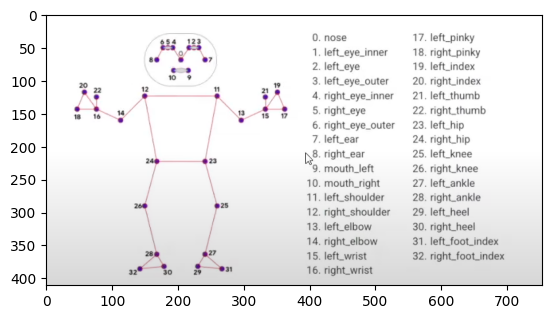

In [3]:
skeleton = cv2.imread("Skeleton.png")
plt.imshow(skeleton)

In [5]:
# USING LIVE WEBCAM

# Set resolution
width, height = 1920, 1080  # Change this to your desired resolution
cap = cv2.VideoCapture(0)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, width)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, height)

with mp_pose.Pose(min_detection_confidence=0.5, min_tracking_confidence=0.5) as pose:
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        # Recolor image to RGB
        image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image.flags.writeable = False

        # Make detection
        results = pose.process(image)

        image.flags.writeable = True
        image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)

        # Draw landmarks
        if results.pose_landmarks:
            mp_drawing.draw_landmarks(image, results.pose_landmarks, mp_pose.POSE_CONNECTIONS)

        # Show the output
        cv2.imshow('Mediapipe Feed', image)
        if cv2.waitKey(10) & 0xFF == ord('q'):
            break

cap.release()
cv2.destroyAllWindows()


In [25]:
# USING PRERECORDED VIDEO

mp_pose = mp.solutions.pose
mp_drawing = mp.solutions.drawing_utils

# Load video file instead of webcam
video_path = "InputVideo.mp4"  # Change this to your video file path
cap = cv2.VideoCapture(video_path)

with mp_pose.Pose(min_detection_confidence=0.5, min_tracking_confidence=0.5) as pose:
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break  # Exit if video ends

        # Recolor image to RGB
        image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image.flags.writeable = False

        # Make detection
        results = pose.process(image)

        image.flags.writeable = True
        image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)

        # Draw landmarks if detected
        if results.pose_landmarks:
            mp_drawing.draw_landmarks(image, results.pose_landmarks, mp_pose.POSE_CONNECTIONS)

        # Show output
        cv2.imshow('Mediapipe Feed', image)
        if cv2.waitKey(10) & 0xFF == ord('q'):  # Press 'q' to quit
            break

cap.release()
cv2.destroyAllWindows()


HANDS

In [28]:
mp_hands = mp.solutions.hands

In [30]:
cap = cv2.VideoCapture(0)

with mp_hands.Hands(min_detection_confidence=0.8, min_tracking_confidence=0.5) as hands: 
    while cap.isOpened():
        ret, frame = cap.read()
        
        # BGR 2 RGB
        image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        
        # Flip on horizontal
        image = cv2.flip(image, 1)
        
        # Set flag
        image.flags.writeable = False
        
        # Detections
        results = hands.process(image)
        
        # Set flag to true
        image.flags.writeable = True
        
        # RGB 2 BGR
        image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
        
        # Detections
        print(results)
        
        # Rendering results
        if results.multi_hand_landmarks:
            for num, hand in enumerate(results.multi_hand_landmarks):
                mp_drawing.draw_landmarks(image, hand, mp_hands.HAND_CONNECTIONS, 
                                        mp_drawing.DrawingSpec(color=(121, 22, 76), thickness=2, circle_radius=4),
                                        mp_drawing.DrawingSpec(color=(250, 44, 250), thickness=2, circle_radius=2),
                                         )
            
        # Save our image    
        cv2.imwrite(os.path.join('Output Images', '{}.jpg'.format(uuid.uuid1())), image)
        cv2.imshow('Hand Tracking', image)

        if cv2.waitKey(10) & 0xFF == ord('q'):
            break

cap.release()
cv2.destroyAllWindows()

<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.soluti

In [31]:
import cv2
import mediapipe as mp

# Initialize MediaPipe Hands and Drawing utilities
mp_hands = mp.solutions.hands
mp_drawing = mp.solutions.drawing_utils

# Initialize webcam
cap = cv2.VideoCapture(0)

# Define a function to classify hand gestures
def classify_gesture(landmarks):
    thumb_tip = landmarks[mp_hands.HandLandmark.THUMB_TIP].x
    index_tip = landmarks[mp_hands.HandLandmark.INDEX_FINGER_TIP].y
    middle_tip = landmarks[mp_hands.HandLandmark.MIDDLE_FINGER_TIP].y
    ring_tip = landmarks[mp_hands.HandLandmark.RING_FINGER_TIP].y
    pinky_tip = landmarks[mp_hands.HandLandmark.PINKY_TIP].y

    # Simple gesture classification logic
    if thumb_tip < landmarks[mp_hands.HandLandmark.INDEX_FINGER_TIP].x:
        return "Thumbs Up"
    elif index_tip < middle_tip and index_tip < ring_tip and index_tip < pinky_tip:
        return "Open Hand"
    else:
        return "Closed Fist"

# Process the webcam feed
with mp_hands.Hands(min_detection_confidence=0.7, min_tracking_confidence=0.7) as hands:
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            print("Ignoring empty camera frame.")
            continue

        # Flip the image horizontally for a later selfie-view display
        frame = cv2.flip(frame, 1)

        # Convert the BGR image to RGB
        image_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Process the image and detect hands
        results = hands.process(image_rgb)

        # Draw hand landmarks and classify gestures
        if results.multi_hand_landmarks:
            for hand_landmarks in results.multi_hand_landmarks:
                # Draw landmarks on the frame
                mp_drawing.draw_landmarks(frame, hand_landmarks, mp_hands.HAND_CONNECTIONS)

                # Classify gesture
                gesture = classify_gesture(hand_landmarks.landmark)
                cv2.putText(frame, gesture, (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2, cv2.LINE_AA)

        # Display the frame
        cv2.imshow('Hand Gesture Detection', frame)

        # Break the loop if 'q' is pressed
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

# Release the webcam and close windows
cap.release()
cv2.destroyAllWindows()

In [32]:
import cv2
import mediapipe as mp
import math

# Initialize MediaPipe Hands and Drawing utilities
mp_hands = mp.solutions.hands
mp_drawing = mp.solutions.drawing_utils

# Initialize webcam
cap = cv2.VideoCapture(0)

# Function to calculate the distance between two landmarks
def calculate_distance(landmark1, landmark2):
    return math.sqrt((landmark1.x - landmark2.x) ** 2 + (landmark1.y - landmark2.y) ** 2)

# Function to classify hand gestures
def classify_gesture(landmarks):
    thumb_tip = landmarks[mp_hands.HandLandmark.THUMB_TIP]
    index_tip = landmarks[mp_hands.HandLandmark.INDEX_FINGER_TIP]
    middle_tip = landmarks[mp_hands.HandLandmark.MIDDLE_FINGER_TIP]
    ring_tip = landmarks[mp_hands.HandLandmark.RING_FINGER_TIP]
    pinky_tip = landmarks[mp_hands.HandLandmark.PINKY_TIP]
    wrist = landmarks[mp_hands.HandLandmark.WRIST]

    # Thumbs Up: Thumb is extended, other fingers are closed
    if (thumb_tip.y < index_tip.y and thumb_tip.y < middle_tip.y and
        thumb_tip.y < ring_tip.y and thumb_tip.y < pinky_tip.y):
        return "Thumbs Up"

    # Peace Sign: Index and Middle fingers are extended, others are closed
    if (index_tip.y < wrist.y and middle_tip.y < wrist.y and
        ring_tip.y > wrist.y and pinky_tip.y > wrist.y):
        return "Peace Sign"

    # OK Sign: Thumb and Index finger tips are close, others are extended
    if (calculate_distance(thumb_tip, index_tip) < 0.05 and
        middle_tip.y > wrist.y and ring_tip.y > wrist.y and pinky_tip.y > wrist.y):
        return "OK Sign"

    # Open Hand: All fingers are extended
    if (index_tip.y < wrist.y and middle_tip.y < wrist.y and
        ring_tip.y < wrist.y and pinky_tip.y < wrist.y):
        return "Open Hand"

    # Closed Fist: All fingers are closed
    if (index_tip.y > wrist.y and middle_tip.y > wrist.y and
        ring_tip.y > wrist.y and pinky_tip.y > wrist.y):
        return "Closed Fist"

    return "Unknown Gesture"

# Process the webcam feed
with mp_hands.Hands(min_detection_confidence=0.7, min_tracking_confidence=0.7) as hands:
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            print("Ignoring empty camera frame.")
            continue

        # Flip the image horizontally for a later selfie-view display
        frame = cv2.flip(frame, 1)

        # Convert the BGR image to RGB
        image_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Process the image and detect hands
        results = hands.process(image_rgb)

        # Draw hand landmarks and classify gestures
        if results.multi_hand_landmarks:
            for hand_landmarks in results.multi_hand_landmarks:
                # Draw landmarks on the frame
                mp_drawing.draw_landmarks(frame, hand_landmarks, mp_hands.HAND_CONNECTIONS)

                # Classify gesture
                gesture = classify_gesture(hand_landmarks.landmark)
                cv2.putText(frame, gesture, (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2, cv2.LINE_AA)

        # Display the frame
        cv2.imshow('Hand Gesture Detection', frame)

        # Break the loop if 'q' is pressed
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

# Release the webcam and close windows
cap.release()
cv2.destroyAllWindows()

In [34]:
import cv2
import mediapipe as mp
import math

# Initialize MediaPipe Hands and Drawing utilities
mp_hands = mp.solutions.hands
mp_drawing = mp.solutions.drawing_utils

# Function to calculate the distance between two landmarks
def calculate_distance(a, b):
    return math.sqrt((a.x - b.x)**2 + (a.y - b.y)**2)

# Function to calculate angle between three landmarks (joint)
def calculate_angle(a, b, c):
    ab = [b.x - a.x, b.y - a.y]
    bc = [c.x - b.x, c.y - b.y]
    dot_product = ab[0] * bc[0] + ab[1] * bc[1]
    magnitude_ab = math.sqrt(ab[0]**2 + ab[1]**2)
    magnitude_bc = math.sqrt(bc[0]**2 + bc[1]**2)
    if magnitude_ab == 0 or magnitude_bc == 0:
        return 0
    return math.degrees(math.acos(dot_product / (magnitude_ab * magnitude_bc)))

# Function to classify hand gestures
def classify_gesture(landmarks):
    wrist = landmarks[mp_hands.HandLandmark.WRIST]
    thumb_tip = landmarks[mp_hands.HandLandmark.THUMB_TIP]
    index_tip = landmarks[mp_hands.HandLandmark.INDEX_FINGER_TIP]
    middle_tip = landmarks[mp_hands.HandLandmark.MIDDLE_FINGER_TIP]
    ring_tip = landmarks[mp_hands.HandLandmark.RING_FINGER_TIP]
    pinky_tip = landmarks[mp_hands.HandLandmark.PINKY_TIP]

    thumb_ip = landmarks[mp_hands.HandLandmark.THUMB_IP]
    index_mcp = landmarks[mp_hands.HandLandmark.INDEX_FINGER_MCP]
    middle_mcp = landmarks[mp_hands.HandLandmark.MIDDLE_FINGER_MCP]
    ring_mcp = landmarks[mp_hands.HandLandmark.RING_FINGER_MCP]
    pinky_mcp = landmarks[mp_hands.HandLandmark.PINKY_MCP]

    # Hand width for normalization (distance from wrist to index base)
    hand_width = calculate_distance(wrist, index_mcp)

    # Thumbs Up - Thumb extended, fingers curled
    thumb_extended = thumb_tip.y < wrist.y
    fingers_curled = all(
        calculate_distance(finger_tip, finger_mcp) / hand_width < 0.4
        for finger_tip, finger_mcp in [
            (index_tip, index_mcp),
            (middle_tip, middle_mcp),
            (ring_tip, ring_mcp),
            (pinky_tip, pinky_mcp)
        ]
    )
    if thumb_extended and fingers_curled:
        return "Thumbs Up"

    # Peace Sign - Index and Middle extended, others curled
    index_extended = calculate_distance(index_tip, index_mcp) / hand_width > 0.5
    middle_extended = calculate_distance(middle_tip, middle_mcp) / hand_width > 0.5
    ring_curled = calculate_distance(ring_tip, ring_mcp) / hand_width < 0.4
    pinky_curled = calculate_distance(pinky_tip, pinky_mcp) < 0.4 * hand_width

    if index_extended and middle_extended and ring_curled and pinky_curled:
        return "Peace Sign"

    # OK Sign - Thumb touches Index, others curled
    thumb_index_distance = calculate_distance(thumb_tip, index_tip) / hand_width
    if thumb_index_distance < 0.15:
        middle_curled = calculate_distance(middle_tip, middle_mcp) / hand_width < 0.4
        ring_curled = calculate_distance(ring_tip, ring_mcp) / hand_width < 0.4
        pinky_curled = calculate_distance(pinky_tip, pinky_mcp) / hand_width < 0.4
        if middle_curled and ring_curled and pinky_curled:
            return "OK Sign"

    # Open Hand - All fingers extended
    fingers_extended = all(
        calculate_distance(finger_tip, finger_mcp) / hand_width > 0.5
        for finger_tip, finger_mcp in [
            (index_tip, index_mcp),
            (middle_tip, middle_mcp),
            (ring_tip, ring_mcp),
            (pinky_tip, pinky_mcp)
        ]
    )
    if fingers_extended:
        return "Open Hand"

    # Closed Fist - All fingers curled
    fingers_curled = all(
        calculate_distance(finger_tip, finger_mcp) / hand_width < 0.4
        for finger_tip, finger_mcp in [
            (index_tip, index_mcp),
            (middle_tip, middle_mcp),
            (ring_tip, ring_mcp),
            (pinky_tip, pinky_mcp)
        ]
    )
    if fingers_curled:
        return "Closed Fist"

    return "Unknown Gesture"

# Initialize webcam
cap = cv2.VideoCapture(0)

# Process the webcam feed
with mp_hands.Hands(min_detection_confidence=0.7, min_tracking_confidence=0.7) as hands:
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            print("Ignoring empty camera frame.")
            continue

        frame = cv2.flip(frame, 1)
        image_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        results = hands.process(image_rgb)

        if results.multi_hand_landmarks:
            for hand_landmarks in results.multi_hand_landmarks:
                mp_drawing.draw_landmarks(frame, hand_landmarks, mp_hands.HAND_CONNECTIONS)

                gesture = classify_gesture(hand_landmarks.landmark)
                cv2.putText(frame, gesture, (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 
                            1, (0, 255, 0), 2, cv2.LINE_AA)

        cv2.imshow('Hand Gesture Detection', frame)

        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

cap.release()
cv2.destroyAllWindows()


Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty camera frame.
Ignoring empty

KeyboardInterrupt: 